In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt

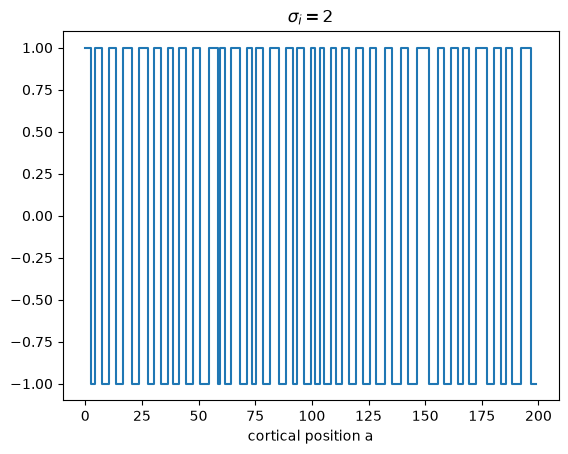

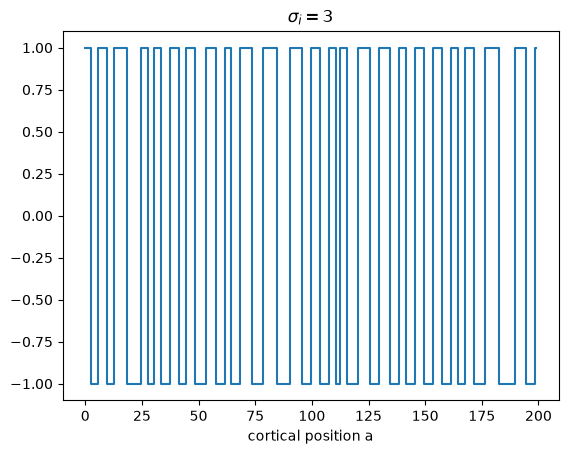

sigma_i  stripe period   2pi/k*  fastest mode period
    2.0     6.40          6.54        6.45
    3.0     8.16          8.48        8.33


In [ ]:
N, sig_e, dt, T = 200, 1.0, 0.02, 40.0
nruns = 20
steps = int(round(T/dt))
idx = np.arange(N); 
d = np.minimum(idx, N-idx)

def mexican_hat(sig_i, sig_e):
    return np.exp(-d**2/(2*sig_e**2)) - (sig_e/sig_i)*np.exp(-d**2/(2*sig_i**2))

def run(sig_i, sig_e):
    w = np.random.normal(0, 0.01, N)
    K = np.fft.fft(mexican_hat(sig_i, sig_e)) # compute the FFT of K 

    for _ in range(steps):
        w = w + dt*np.real(np.fft.ifft(K*np.fft.fft(w))) # use that sum(K((a - b) mod N) * w_(b)) = ifft(fft(K) * fft(w_))(a) (circular convolution)
        np.clip(w, -1, 1, out=w)

    return w

def period(w):
    s = np.sign(w); s[s == 0] = 1
    changes = np.sum(s != np.roll(s, 1)) 
    pairs = changes // 2
    return N/pairs if pairs else np.inf

res, finals = {}, {}

for sig_i in (2.0, 3.0):
    ks = np.sqrt(4*np.log(sig_i/sig_e)/(sig_i**2 - sig_e**2))
    Kt = np.real(np.fft.fft(mexican_hat(sig_i, sig_e))) 
    m = np.arange(1, N//2+1)
    fastmode = m[np.argmax(Kt[1:N//2+1])]
    per = [period(run(sig_i, sig_e)) for s in range(nruns)]
    finals[sig_i] = run(sig_i, sig_e);
    res[sig_i] = dict(kstar=ks, P_cont=2*np.pi/ks, mbest=fastmode, P_ring=N/fastmode,
                      Kt_rate=Kt[fastmode], P_mean=np.mean(per), periods=per)

plt.step(idx, finals[2.0], where="mid")
plt.title(r"$\sigma_i=2$")
plt.xlabel("cortical position a")
plt.show()

plt.step(idx, finals[3.0], where="mid")
plt.title(r"$\sigma_i=3$")
plt.xlabel("cortical position a")
plt.show()


print(f"{'sigma_i':>7}  {'stripe period':>7}  {'2pi/k*':>7}  {'fastest mode period':>8}")
for sig_i, r in res.items():
    print(f"{sig_i:>7}  {r['P_mean']:>7.2f}  {r['P_cont']:>12.2f}  {r['P_ring']:>10.2f}")

lambda = 0.2, theta = 4:  accuracy = 0.819,  mean time = 8.22
perfect integrator, theta = 1.89:  accuracy = 0.820,  mean time = 6.15


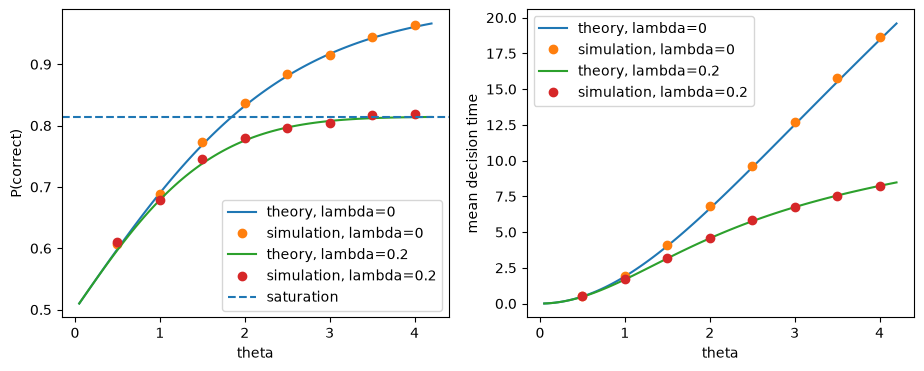

In [67]:
from scipy.integrate import quad, solve_bvp
from scipy.stats import norm

mu, sig, I0 = 0.2, 0.5, 5
lams = [0, 0.2]
dt, Nt = 0.002, 10_000
thetas = np.arange(0.5, 4.5, 0.5)


def euler_maruyama_step(r1, r2, lam, dt):
    w_s = w_c = (1 + lam) / 2
    noise1 = sig * np.sqrt(dt) * np.random.randn(len(r1))
    noise2 = sig * np.sqrt(dt) * np.random.randn(len(r1))
    dr1 = (-r1 + w_s * r1 - w_c * r2 + I0 + mu / 2) * dt + noise1
    dr2 = (-r2 + w_s * r2 - w_c * r1 + I0 - mu / 2) * dt + noise2
    return r1 + dr1, r2 + dr2


def simulate(lam, theta):
    r1 = np.full(Nt, I0, dtype=float)
    r2 = np.full(Nt, I0, dtype=float)
    decided = np.zeros(Nt, dtype=bool)
    correct = np.zeros(Nt, dtype=bool)
    decision_time = np.zeros(Nt)
    t = 0

    while not decided.all():
        undecided = ~decided
        r1[undecided], r2[undecided] = euler_maruyama_step(r1[undecided], r2[undecided], lam, dt)
        t += dt
        d = r1 - r2
        just_decided = undecided & (np.abs(d) >= theta)
        correct[just_decided] = d[just_decided] > 0
        decision_time[just_decided] = t
        decided |= just_decided

    return correct.mean(), decision_time.mean()


def theory_perfect_integrator(theta):
    accuracy = 1 / (1 + np.exp(-mu * theta / sig**2))
    mean_time = theta / mu * np.tanh(mu * theta / (2 * sig**2))
    return accuracy, mean_time


def theory_unstable_integrator(lam, theta):
    g = lambda y: np.exp(-(lam * y**2 + 2 * mu * y) / (2 * sig**2))
    accuracy = quad(g, -theta, 0)[0] / quad(g, -theta, theta)[0]

    def mean_time_ode(x, y):
        T, dT = y
        return [dT, (-1 - (lam * x + mu) * dT) / sig**2]

    def boundary_conditions(T_left, T_right):
        return [T_left[0], T_right[0]]

    x = np.linspace(-theta, theta, 200)
    solution = solve_bvp(mean_time_ode, boundary_conditions, x, np.zeros((2, x.size)))
    mean_time = solution.sol(0)[0]
    return accuracy, mean_time


def theory(lam, theta):
    if lam == 0:
        return theory_perfect_integrator(theta)
    return theory_unstable_integrator(lam, theta)


simulated = {lam: np.array([simulate(lam, theta) for theta in thetas]) for lam in lams}

theta_fine = np.linspace(0.05, 4.2, 100)
predicted = {lam: np.array([theory(lam, theta) for theta in theta_fine]) for lam in lams}
saturation_accuracy = norm.cdf(mu / (sig * np.sqrt(0.2)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(theta_fine, predicted[0][:, 0], label="theory, lambda=0")
ax[0].plot(thetas, simulated[0][:, 0], "o", label="simulation, lambda=0")
ax[0].plot(theta_fine, predicted[0.2][:, 0], label="theory, lambda=0.2")
ax[0].plot(thetas, simulated[0.2][:, 0], "o", label="simulation, lambda=0.2")
ax[0].axhline(saturation_accuracy, linestyle="--", label="saturation")
ax[0].set_xlabel("theta")
ax[0].set_ylabel("P(correct)")
ax[0].legend()
ax[1].plot(theta_fine, predicted[0][:, 1], label="theory, lambda=0")
ax[1].plot(thetas, simulated[0][:, 1], "o", label="simulation, lambda=0")
ax[1].plot(theta_fine, predicted[0.2][:, 1], label="theory, lambda=0.2")
ax[1].plot(thetas, simulated[0.2][:, 1], "o", label="simulation, lambda=0.2")
ax[1].set_xlabel("theta")
ax[1].set_ylabel("mean decision time")
ax[1].legend()

accuracy, mean_time = simulated[0.2][-1]
theta_same_accuracy = sig**2 / mu * np.log(accuracy / (1 - accuracy))
accuracy_perfect, mean_time_perfect = simulate(0, theta_same_accuracy)

print(f"lambda = 0.2, theta = 4:  accuracy = {accuracy:.3f},  mean time = {mean_time:.2f}")
print(f"perfect integrator, theta = {theta_same_accuracy:.2f}:  "
      f"accuracy = {accuracy_perfect:.3f},  mean time = {mean_time_perfect:.2f}")

In [18]:
# 3b
from scipy.optimize import brentq
alpha = brentq(lambda a: norm.cdf(-1/a**0.5) - 0.01, 1e-6, 10)
print(alpha)

0.184778179386101


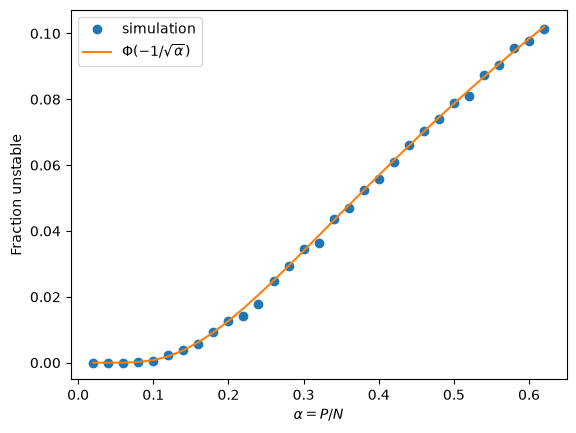

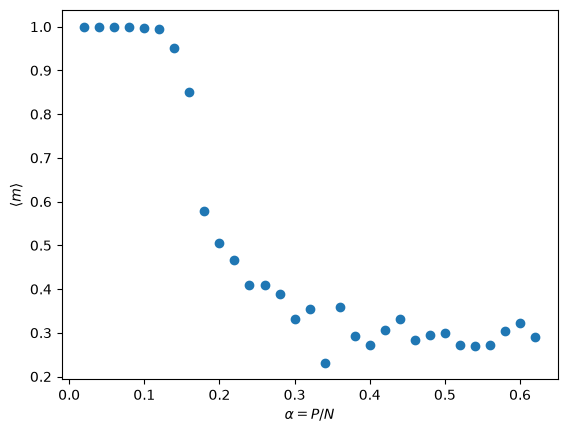

In [66]:
# 3c
N = 500
als = np.linspace(start=0.02, stop=0.62, num=31)
frac_unstable = []
n_trials = 10
mbars = []

for a in als:
    P = int(round(a*N))
    rng = np.random.default_rng()

    xis = rng.choice([-1, 1], size=(P, N))

    W = xis.T @ xis / N    
    np.fill_diagonal(W, 0)

    H = xis @ W 

    # i 
    frac_unstable.append(np.mean(xis * H < 0))

    # ii
    m = []

    for i in range(n_trials):
        random_mu = rng.choice(range(P))
        s = xis[random_mu].copy()
        flip = rng.choice(N, size=int(round(0.1 * N)), replace=False)
        s[flip] *= -1   

        while True:
            changed = False

            for i in rng.permutation(N):
                h = W[i] @ s
                new = s[i] if h == 0 else (1 if h > 0 else -1)
                if new != s[i]:
                    s[i] = new
                    changed = True

            if not changed:
                break

        m.append((1/N)*(xis[random_mu]@s))

    mbars.append(np.mean(m))
    
    
plt.plot(als, frac_unstable, 'o', label='simulation')
plt.plot(als, norm.cdf(-1/np.sqrt(als)), '-', label=r'$\Phi(-1/\sqrt{\alpha})$')
plt.xlabel(r'$\alpha = P/N$')
plt.ylabel('Fraction unstable')
plt.legend()
plt.show()

plt.plot(als, mbars, 'o')
plt.xlabel(r'$\alpha = P/N$')
plt.ylabel(r'$\langle m \rangle$')
plt.show()
